In [1]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/deepfake-defense"
)

print("Project exists:", PROJECT_ROOT.exists())

print("\nProject contents:")
for item in PROJECT_ROOT.iterdir():
    print(" -", item.name)

Project exists: True

Project contents:
 - datasets
 - checkpoints
 - experiments
 - reports
 - models


In [ ]:
!pip install -q timm

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
MANIFEST_PATH = (
    PROJECT_ROOT
    / "datasets"
    / "processed"
    / "manifest_with_split.csv"
)

df = pd.read_csv(MANIFEST_PATH)

print("Total images:", len(df))
print("\nSplit:")
print(df["split"].value_counts())

print("\nClasses:")
print(df["class"].value_counts())

Total images: 2000

Split:
split
train    1400
val       300
test      300
Name: count, dtype: int64

Classes:
class
REAL    1000
FAKE    1000
Name: count, dtype: int64


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=5
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DeepfakeDataset(Dataset):

    def __init__(
        self,
        dataframe,
        transform=None
    ):
        self.dataframe = dataframe.reset_index(
            drop=True
        )
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        row = self.dataframe.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return image, label

In [ ]:
train_df = df[df["split"] == "train"].copy()
val_df = df[df["split"] == "val"].copy()
test_df = df[df["split"] == "test"].copy()

train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform=eval_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=eval_transform
)

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train:", len(train_dataset))
print("Val:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 1400
Val: 300
Test: 300


In [ ]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])


In [ ]:
def fft_decompose(images):
    """
    Convert spatial images into frequency-domain representations.

    Input:
        images: [B, C, H, W]

    Returns:
        magnitude: frequency magnitude
        phase: frequency phase
    """

    # 2D FFT
    fft = torch.fft.fft2(
        images,
        dim=(-2, -1)
    )

    # Move low frequencies to the center
    fft_shifted = torch.fft.fftshift(
        fft,
        dim=(-2, -1)
    )

    # Magnitude
    magnitude = torch.abs(
        fft_shifted
    )

    # Phase
    phase = torch.angle(
        fft_shifted
    )

    # Log scaling makes frequency information easier to analyze
    magnitude = torch.log1p(
        magnitude
    )

    return magnitude, phase


magnitude, phase = fft_decompose(images)

print("Input shape:     ", images.shape)
print("Magnitude shape: ", magnitude.shape)
print("Phase shape:     ", phase.shape)

Input shape:      torch.Size([32, 3, 224, 224])
Magnitude shape:  torch.Size([32, 3, 224, 224])
Phase shape:      torch.Size([32, 3, 224, 224])


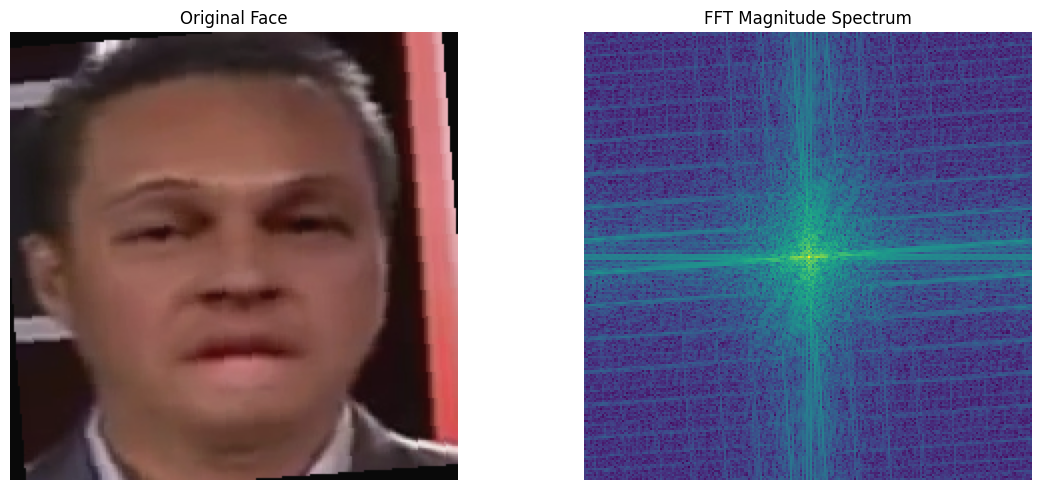

In [ ]:
# Take the first image
image = images[0]

# Take its frequency magnitude
freq = magnitude[0]

# Convert RGB frequency information to a single visualization
freq_gray = freq.mean(dim=0)

# Move to CPU
freq_gray = freq_gray.detach().cpu().numpy()

# Original image
original = image.detach().cpu()

# Undo ImageNet normalization for visualization
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

original = original * std + mean
original = torch.clamp(
    original,
    0,
    1
)

original = original.permute(
    1, 2, 0
).numpy()


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Face")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(freq_gray)
plt.title("FFT Magnitude Spectrum")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
class AdaptiveFrequencyGate(nn.Module):
    """
    Learns input-dependent weights for frequency features.

    Input:
        [B, C, H, W]

    Output:
        [B, C, H, W]
    """

    def __init__(self, channels=3, reduction=8):

        super().__init__()

        hidden_channels = max(
            channels // reduction,
            1
        )

        self.gate = nn.Sequential(

            nn.Conv2d(
                channels,
                hidden_channels,
                kernel_size=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                hidden_channels,
                channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        # Global frequency statistics
        pooled = F.adaptive_avg_pool2d(
            x,
            output_size=1
        )

        # Learn channel-wise frequency importance
        weights = self.gate(
            pooled
        )

        # Apply adaptive weights
        enhanced = x * weights

        return enhanced, weights


# Create gate
frequency_gate = AdaptiveFrequencyGate(
    channels=3
)

frequency_gate = frequency_gate.to(device)

print(frequency_gate)

AdaptiveFrequencyGate(
  (gate): Sequential(
    (0): Conv2d(3, 1, kernel_size=(1, 1), stride=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(1, 3, kernel_size=(1, 1), stride=(1, 1))
    (3): Sigmoid()
  )
)


In [ ]:
def afem_reconstruct(images, frequency_gate):
    """
    Perform FFT-based adaptive frequency enhancement
    and reconstruct the spatial representation.

    Input:
        images: [B, C, H, W]

    Returns:
        enhanced_images: [B, C, H, W]
        weights: adaptive frequency weights
    """

    # --------------------------------
    # 1. FFT
    # --------------------------------
    fft = torch.fft.fft2(
        images,
        dim=(-2, -1)
    )

    # --------------------------------
    # 2. Shift low frequencies
    # --------------------------------
    fft_shifted = torch.fft.fftshift(
        fft,
        dim=(-2, -1)
    )

    # --------------------------------
    # 3. Magnitude and phase
    # --------------------------------
    magnitude = torch.abs(fft_shifted)
    phase = torch.angle(fft_shifted)

    # Log scaling for stable frequency processing
    magnitude_log = torch.log1p(magnitude)

    # --------------------------------
    # 4. Adaptive frequency gating
    # --------------------------------
    enhanced_magnitude_log, weights = frequency_gate(
        magnitude_log
    )

    # Convert back from log scale
    enhanced_magnitude = torch.expm1(
        enhanced_magnitude_log
    )

    # --------------------------------
    # 5. Reconstruct complex spectrum
    # --------------------------------
    enhanced_fft_shifted = (
        enhanced_magnitude *
        torch.exp(1j * phase)
    )

    # --------------------------------
    # 6. Undo FFT shift
    # --------------------------------
    enhanced_fft = torch.fft.ifftshift(
        enhanced_fft_shifted,
        dim=(-2, -1)
    )

    # --------------------------------
    # 7. Inverse FFT
    # --------------------------------
    enhanced_images = torch.fft.ifft2(
        enhanced_fft,
        dim=(-2, -1)
    ).real

    return enhanced_images, weights

In [ ]:
images, labels = next(iter(train_loader))

images = images.to(device)

enhanced_images, weights = afem_reconstruct(
    images,
    frequency_gate
)

print("Original shape:",
      images.shape)

print("Enhanced shape:",
      enhanced_images.shape)

print("Weights shape:",
      weights.shape)

print(
    "Original range:",
    images.min().item(),
    "to",
    images.max().item()
)

print(
    "Enhanced range:",
    enhanced_images.min().item(),
    "to",
    enhanced_images.max().item()
)

Original shape: torch.Size([32, 3, 224, 224])
Enhanced shape: torch.Size([32, 3, 224, 224])
Weights shape: torch.Size([32, 3, 1, 1])
Original range: -2.1179039478302 to 2.640000104904175
Enhanced range: -1.703570008277893 to 1.4264124631881714


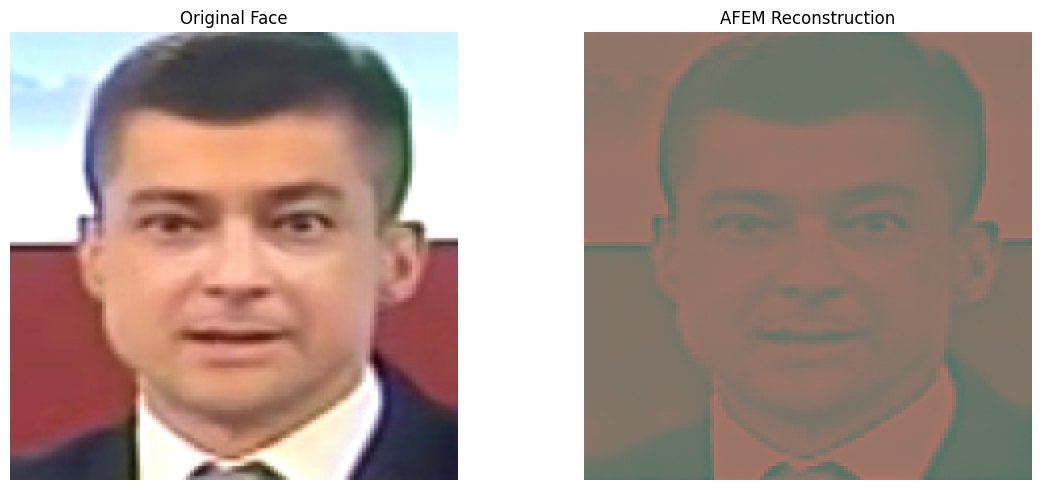

In [ ]:
def denormalize(image):

    mean = torch.tensor(
        [0.485, 0.456, 0.406],
        device=image.device
    ).view(3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225],
        device=image.device
    ).view(3, 1, 1)

    image = image * std + mean

    return torch.clamp(
        image,
        0,
        1
    )


original = denormalize(
    images[0]
).detach().cpu()

enhanced = denormalize(
    enhanced_images[0]
).detach().cpu()

original = original.permute(
    1, 2, 0
).numpy()

enhanced = enhanced.permute(
    1, 2, 0
).numpy()


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Face")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(enhanced)
plt.title("AFEM Reconstruction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
class AdaptiveFrequencyMask(nn.Module):
    """
    Learns an input-dependent spatial mask over the
    frequency magnitude spectrum.

    The mask is frequency-location aware rather than
    producing only one weight per RGB channel.
    """

    def __init__(self, channels=3):
        super().__init__()

        self.mask_network = nn.Sequential(

            nn.Conv2d(
                channels,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

    def forward(self, magnitude):

        # Normalize frequency magnitude per image
        mean = magnitude.mean(
            dim=(-2, -1),
            keepdim=True
        )

        std = magnitude.std(
            dim=(-2, -1),
            keepdim=True
        ) + 1e-6

        normalized = (
            magnitude - mean
        ) / std

        # Learn frequency-specific importance
        mask = self.mask_network(
            normalized
        )

        return mask

In [ ]:
frequency_mask = AdaptiveFrequencyMask(
    channels=3
).to(device)

# Get one batch
images, labels = next(iter(train_loader))

images = images.to(device)

# FFT
fft = torch.fft.fft2(
    images,
    dim=(-2, -1)
)

fft_shifted = torch.fft.fftshift(
    fft,
    dim=(-2, -1)
)

magnitude = torch.abs(
    fft_shifted
)

magnitude_log = torch.log1p(
    magnitude
)

# Generate adaptive frequency mask
mask = frequency_mask(
    magnitude_log
)

print("Magnitude:",
      magnitude_log.shape)

print("Adaptive mask:",
      mask.shape)

print(
    "Mask range:",
    mask.min().item(),
    "to",
    mask.max().item()
)

Magnitude: torch.Size([32, 3, 224, 224])
Adaptive mask: torch.Size([32, 3, 224, 224])
Mask range: 0.42524823546409607 to 0.599682092666626


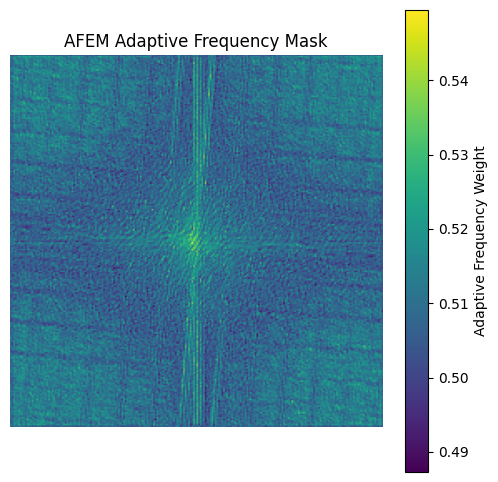

In [ ]:
mask_visual = mask[0].mean(
    dim=0
).detach().cpu().numpy()

plt.figure(figsize=(6, 6))

plt.imshow(mask_visual)

plt.colorbar(
    label="Adaptive Frequency Weight"
)

plt.title(
    "AFEM Adaptive Frequency Mask"
)

plt.axis("off")

plt.show()

In [ ]:
class AFEM(nn.Module):
    """
    Adaptive Frequency Enhancement Module.

    Pipeline:
        Input
          ↓
        FFT
          ↓
        Frequency magnitude
          ↓
        Adaptive frequency mask
          ↓
        Frequency enhancement
          ↓
        Inverse FFT
          ↓
        Enhanced spatial representation
    """

    def __init__(
        self,
        channels=3,
        enhancement_strength=1.0
    ):
        super().__init__()

        self.enhancement_strength = enhancement_strength

        # Adaptive frequency mask
        self.mask_network = nn.Sequential(

            nn.Conv2d(
                channels,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        # =====================================
        # 1. FFT
        # =====================================

        fft = torch.fft.fft2(
            x,
            dim=(-2, -1)
        )

        fft_shifted = torch.fft.fftshift(
            fft,
            dim=(-2, -1)
        )

        # =====================================
        # 2. Magnitude + phase
        # =====================================

        magnitude = torch.abs(
            fft_shifted
        )

        phase = torch.angle(
            fft_shifted
        )

        # Log magnitude for stable learning
        magnitude_log = torch.log1p(
            magnitude
        )

        # =====================================
        # 3. Normalize frequency representation
        # =====================================

        mean = magnitude_log.mean(
            dim=(-2, -1),
            keepdim=True
        )

        std = magnitude_log.std(
            dim=(-2, -1),
            keepdim=True
        ) + 1e-6

        normalized = (
            magnitude_log - mean
        ) / std

        # =====================================
        # 4. Adaptive frequency mask
        # =====================================

        mask = self.mask_network(
            normalized
        )

        # =====================================
        # 5. Adaptive enhancement
        # =====================================

        # Baseline preservation + adaptive enhancement
        enhanced_magnitude_log = (
            magnitude_log *
            (
                1.0 +
                self.enhancement_strength * mask
            )
        )

        # Convert back from logarithmic scale
        enhanced_magnitude = torch.expm1(
            enhanced_magnitude_log
        )

        # =====================================
        # 6. Reconstruct complex spectrum
        # =====================================

        enhanced_fft_shifted = (
            enhanced_magnitude *
            torch.exp(1j * phase)
        )

        # =====================================
        # 7. Undo FFT shift
        # =====================================

        enhanced_fft = torch.fft.ifftshift(
            enhanced_fft_shifted,
            dim=(-2, -1)
        )

        # =====================================
        # 8. Inverse FFT
        # =====================================

        enhanced = torch.fft.ifft2(
            enhanced_fft,
            dim=(-2, -1)
        ).real

        return enhanced, mask

In [ ]:
afem = AFEM(
    channels=3,
    enhancement_strength=1.0
).to(device)

print(afem)

AFEM(
  (mask_network): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(16, 3, kernel_size=(1, 1), stride=(1, 1))
    (5): Sigmoid()
  )
)


In [ ]:
images, labels = next(
    iter(train_loader)
)

images = images.to(device)

enhanced_images, frequency_mask = afem(
    images
)

print("Input:")
print(images.shape)

print("\nAFEM output:")
print(enhanced_images.shape)

print("\nFrequency mask:")
print(frequency_mask.shape)

print("\nMask range:")
print(
    frequency_mask.min().item(),
    "to",
    frequency_mask.max().item()
)

Input:
torch.Size([32, 3, 224, 224])

AFEM output:
torch.Size([32, 3, 224, 224])

Frequency mask:
torch.Size([32, 3, 224, 224])

Mask range:
0.3263213038444519 to 0.5460693836212158


In [ ]:
print(
    "AFEM parameters:",
    sum(p.numel() for p in afem.parameters())
)

print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in afem.parameters()
        if p.requires_grad
    )
)

AFEM parameters: 2819
Trainable parameters: 2819


In [ ]:
# Get one batch
images, labels = next(iter(train_loader))

images = images.to(device)

# Enable gradient tracking
images.requires_grad_(True)

# Forward through AFEM
enhanced_images, frequency_mask = afem(images)

# Simple test loss
loss = enhanced_images.mean()

# Backpropagation
loss.backward()

print("Loss:", loss.item())

print(
    "Gradient exists:",
    images.grad is not None
)

print(
    "AFEM gradient exists:",
    afem.mask_network[0].weight.grad is not None
)

print(
    "Gradient mean:",
    afem.mask_network[0].weight.grad.abs().mean().item()
)

Loss: 4.503213882446289
Gradient exists: True
AFEM gradient exists: True
Gradient mean: 2.298614263534546


In [ ]:
import timm
import torch.nn as nn

# Create pretrained Xception
xception_afem = timm.create_model(
    "xception",
    pretrained=True,
    num_classes=2
)

xception_afem = xception_afem.to(device)

print("Xception loaded successfully.")

/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Xception loaded successfully.


In [ ]:
class AFEMXception(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        # AFEM
        self.afem = AFEM(
            channels=3,
            enhancement_strength=1.0
        )

        # Xception backbone
        self.xception = timm.create_model(
            "xception",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):

        # Frequency enhancement
        enhanced, mask = self.afem(x)

        # Xception classification
        output = self.xception(
            enhanced
        )

        return output, mask


model = AFEMXception(
    num_classes=2
).to(device)

print(model)

AFEMXception(
  (afem): AFEM(
    (mask_network): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): Conv2d(16, 3, kernel_size=(1, 1), stride=(1, 1))
      (5): Sigmoid()
    )
  )
  (xception): Xception(
    (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act2): ReLU(inplace=True)
    (block1): Block(
      (skip): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (skipbn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (rep): Sequentia

In [ ]:
model.eval()

images, labels = next(
    iter(train_loader)
)

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():

    outputs, masks = model(
        images
    )

print("Input shape:")
print(images.shape)

print("\nClassification output:")
print(outputs.shape)

print("\nFrequency mask:")
print(masks.shape)

Input shape:
torch.Size([32, 3, 224, 224])

Classification output:
torch.Size([32, 2])

Frequency mask:
torch.Size([32, 3, 224, 224])


In [ ]:
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 0.0001
)


In [ ]:
model.train()

images, labels = next(
    iter(train_loader)
)

images = images.to(device)
labels = labels.to(device)

# Clear previous gradients
optimizer.zero_grad()

# Forward
outputs, masks = model(images)

# Classification loss
loss = criterion(
    outputs,
    labels
)

# Backpropagation
loss.backward()

print("Classification loss:", loss.item())

# Check AFEM gradient
afem_grad = (
    model.afem.mask_network[0]
    .weight.grad
)

print(
    "AFEM gradient exists:",
    afem_grad is not None
)

print(
    "AFEM gradient mean:",
    afem_grad.abs().mean().item()
)

# Check Xception gradient
xception_grad = (
    model.xception.conv1
    .weight.grad
)

print(
    "Xception gradient exists:",
    xception_grad is not None
)

Classification loss: 0.7203313708305359
AFEM gradient exists: True
AFEM gradient mean: 0.008720963262021542
Xception gradient exists: True


In [ ]:
from tqdm.auto import tqdm


def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        # Clear gradients
        optimizer.zero_grad()

        # Forward
        outputs, masks = model(images)

        # Classification loss
        loss = criterion(
            outputs,
            labels
        )

        # Backpropagation
        loss.backward()

        # Update parameters
        optimizer.step()

        # Statistics
        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

        progress.set_postfix(
            loss=loss.item()
        )

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return epoch_loss, epoch_accuracy


@torch.no_grad()
def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        outputs, masks = model(images)

        loss = criterion(
            outputs,
            labels
        )

        running_loss += (
            loss.item() * images.size(0)
        )

        predictions = outputs.argmax(
            dim=1
        )

        correct += (
            predictions == labels
        ).sum().item()

        total += labels.size(0)

    epoch_loss = (
        running_loss / total
    )

    epoch_accuracy = (
        correct / total
    )

    return epoch_loss, epoch_accuracy

In [ ]:
from pathlib import Path

NUM_EPOCHS = 10

CHECKPOINT_DIR = (
    PROJECT_ROOT / "checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

BEST_MODEL_PATH = (
    CHECKPOINT_DIR /
    "afem_xception_best.pth"
)

history = []

best_val_accuracy = 0.0


for epoch in range(1, NUM_EPOCHS + 1):

    print(
        f"\n========== Epoch {epoch}/{NUM_EPOCHS} =========="
    )

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_acc = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc
    })

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.4f}"
    )

    print(
        f"Val Loss:   {val_loss:.4f} | "
        f"Val Acc:   {val_acc:.4f}"
    )

    # Save best model
    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_accuracy": val_acc,
                "val_loss": val_loss
            },
            BEST_MODEL_PATH
        )

        print(
            "✓ Best model saved:",
            BEST_MODEL_PATH
        )


history_df = pd.DataFrame(history)

print("\nTraining complete.")
print(
    "Best validation accuracy:",
    best_val_accuracy
)


========== Epoch 1/10 ==========


Training:   0%|          | 0/44 [00:00<?, ?it/s]

Train Loss: 0.4947 | Train Acc: 0.7650
Val Loss:   0.6054 | Val Acc:   0.7067
✓ Best model saved: /content/drive/MyDrive/deepfake-defense/checkpoints/afem_xception_best.pth

========== Epoch 2/10 ==========


Training:   0%|          | 0/44 [00:00<?, ?it/s]

Train Loss: 0.1409 | Train Acc: 0.9536
Val Loss:   0.7648 | Val Acc:   0.7267
✓ Best model saved: /content/drive/MyDrive/deepfake-defense/checkpoints/afem_xception_best.pth

========== Epoch 3/10 ==========


...

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a7de46da0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a7de46da0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Train Loss: 0.0453 | Train Acc: 0.9829
Val Loss:   0.7865 | Val Acc:   0.6467

========== Epoch 10/10 ==========


Training:   0%|          | 0/44 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a7de46da0c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
<function _MultiProcessingDataLoaderIter.__del__ at 0x7a7de46da0c0>    
if w.is_alive():Traceback (most recent call last):

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
AssertionError    : if w.is_alive():
can only test a child process  File "/usr/lib/p

Train Loss: 0.0327 | Train Acc: 0.9886
Val Loss:   0.8148 | Val Acc:   0.6367

Training complete.
Best validation accuracy: 0.74


In [ ]:
from pathlib import Path

BEST_MODEL_PATH = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "checkpoints/afem_xception_best.pth"
)

print("Checkpoint exists:", BEST_MODEL_PATH.exists())

if BEST_MODEL_PATH.exists():
    print("Checkpoint:", BEST_MODEL_PATH)
    print("Size (MB):", BEST_MODEL_PATH.stat().st_size / (1024**2))

Checkpoint exists: True
Checkpoint: /content/drive/MyDrive/deepfake-defense/checkpoints/afem_xception_best.pth
Size (MB): 238.63122653961182


In [ ]:
# Load the best AFEM + Xception checkpoint

checkpoint = torch.load(
    BEST_MODEL_PATH,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

best_epoch = checkpoint["epoch"]
best_val_acc = checkpoint["val_accuracy"]

print("Best epoch:", best_epoch)
print("Best validation accuracy:", best_val_acc)

model.eval()

Best epoch: 7
Best validation accuracy: 0.74


AFEMXception(
  (afem): AFEM(
    (mask_network): Sequential(
      (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU(inplace=True)
      (4): Conv2d(16, 3, kernel_size=(1, 1), stride=(1, 1))
      (5): Sigmoid()
    )
  )
  (xception): Xception(
    (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), bias=False)
    (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act1): ReLU(inplace=True)
    (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), bias=False)
    (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act2): ReLU(inplace=True)
    (block1): Block(
      (skip): Conv2d(64, 128, kernel_size=(1, 1), stride=(2, 2), bias=False)
      (skipbn): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (rep): Sequentia

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

all_labels = []
all_predictions = []
all_probabilities = []


with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs, masks = model(images)

        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        # Probability of FAKE class
        all_probabilities.extend(
            probabilities[:, 1]
            .cpu()
            .numpy()
        )


# Convert to arrays
all_labels = np.array(all_labels)
all_predictions = np.array(all_predictions)
all_probabilities = np.array(all_probabilities)


# Metrics
accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision = precision_score(
    all_labels,
    all_predictions,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_predictions,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_predictions,
    zero_division=0
)

auc = roc_auc_score(
    all_labels,
    all_probabilities
)

cm = confusion_matrix(
    all_labels,
    all_predictions
)


print("================================")
print("AFEM + XCEPTION TEST RESULTS")
print("================================")

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC-AUC  : {auc:.4f}")

print("\nConfusion Matrix:")
print(cm)

AFEM + XCEPTION TEST RESULTS
Accuracy : 0.5100
Precision: 0.5081
Recall   : 0.6267
F1 Score : 0.5612
ROC-AUC  : 0.5469

Confusion Matrix:
[[59 91]
 [56 94]]


In [ ]:
print("VIDEO COUNTS")
print(
    df.groupby(["split", "class"])["video_id"]
      .nunique()
)

print("\nIMAGE COUNTS")
print(
    df.groupby(["split", "class"])
      .size()
)

VIDEO COUNTS
split  class
test   FAKE     15
       REAL     15
train  FAKE     70
       REAL     70
val    FAKE     15
       REAL     15
Name: video_id, dtype: int64

IMAGE COUNTS
split  class
test   FAKE     150
       REAL     150
train  FAKE     700
       REAL     700
val    FAKE     150
       REAL     150
dtype: int64


In [ ]:
print("\nREAL videos by split:")
for split in ["train", "val", "test"]:
    ids = sorted(
        df[
            (df["split"] == split) &
            (df["class"] == "REAL")
        ]["video_id"].unique()
    )
    print(split, ids[:20])


print("\nFAKE videos by split:")
for split in ["train", "val", "test"]:
    ids = sorted(
        df[
            (df["split"] == split) &
            (df["class"] == "FAKE")
        ]["video_id"].unique()
    )
    print(split, ids[:20])


REAL videos by split:
train ['033', '044', '046', '055', '062', '066', '097', '107', '109', '128', '134', '147', '153', '159', '168', '175', '183', '210', '222', '241']
val ['035', '036', '150', '221', '257', '481', '522', '589', '633', '677', '716', '720', '828', '866', '917']
test ['192', '206', '266', '337', '396', '441', '572', '585', '588', '896', '904', '943', '945', '969', '992']

FAKE videos by split:
train ['035_036', '044_945', '055_147', '107_109', '109_107', '134_192', '153_150', '159_175', '168_222', '175_159', '183_253', '192_134', '206_221', '221_206', '222_168', '241_210', '254_261', '257_420', '261_254', '263_284']
val ['033_097', '036_035', '046_904', '062_066', '066_062', '147_055', '150_153', '252_266', '266_252', '272_396', '284_263', '677_671', '830_828', '974_953', '980_992']
test ['097_033', '128_896', '210_241', '253_183', '321_288', '392_339', '434_438', '438_434', '439_441', '599_585', '644_657', '683_607', '794_779', '969_897', '986_994']


In [ ]:
from pathlib import Path
import pandas as pd

manifest = pd.read_csv(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_with_split.csv"
)

fake_videos = sorted(
    manifest[
        manifest["class"] == "FAKE"
    ]["video_id"].unique()
)

print("Total fake videos:", len(fake_videos))

print("\nFake video → source/target IDs:\n")

for video_id in fake_videos[:30]:

    parts = video_id.split("_")

    if len(parts) == 2:
        source_id, target_id = parts

        print(
            f"{video_id:12s}"
            f" source={source_id:4s}"
            f" target={target_id:4s}"
        )
    else:
        print(video_id)

Total fake videos: 100

Fake video → source/target IDs:

033_097      source=033  target=097 
035_036      source=035  target=036 
036_035      source=036  target=035 
044_945      source=044  target=945 
046_904      source=046  target=904 
055_147      source=055  target=147 
062_066      source=062  target=066 
066_062      source=066  target=062 
097_033      source=097  target=033 
107_109      source=107  target=109 
109_107      source=109  target=107 
128_896      source=128  target=896 
134_192      source=134  target=192 
147_055      source=147  target=055 
150_153      source=150  target=153 
153_150      source=153  target=150 
159_175      source=159  target=175 
168_222      source=168  target=222 
175_159      source=175  target=159 
183_253      source=183  target=253 
192_134      source=192  target=134 
206_221      source=206  target=221 
210_241      source=210  target=241 
221_206      source=221  target=206 
222_168      source=222  target=168 
241_210      sourc

In [ ]:
import pandas as pd
from pathlib import Path

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_with_split.csv"
)

df = pd.read_csv(MANIFEST_PATH)

# --------------------------------------------------
# Collect all REAL video IDs
# --------------------------------------------------

real_ids = set(
    df[df["class"] == "REAL"]["video_id"].astype(str)
)

# --------------------------------------------------
# Build groups from fake source/target relationships
# --------------------------------------------------

groups = {}
visited = set()

fake_ids = sorted(
    df[df["class"] == "FAKE"]["video_id"]
    .astype(str)
    .unique()
)

for fake_id in fake_ids:

    source, target = fake_id.split("_")

    if source in visited or target in visited:
        continue

    group = {source, target}

    # Include fake videos connecting these two IDs
    for fid in fake_ids:
        a, b = fid.split("_")

        if a in group or b in group:
            group.add(a)
            group.add(b)

    group_name = "_".join(sorted(group))

    groups[group_name] = sorted(group)

    visited.update(group)


print("Number of groups:", len(groups))

print("\nFirst 15 groups:")

for name, members in list(groups.items())[:15]:
    print(name, "→", members)

Number of groups: 50

First 15 groups:
033_097 → ['033', '097']
035_036 → ['035', '036']
044_945 → ['044', '945']
046_904 → ['046', '904']
055_147 → ['055', '147']
062_066 → ['062', '066']
107_109 → ['107', '109']
128_896 → ['128', '896']
134_192 → ['134', '192']
150_153 → ['150', '153']
159_175 → ['159', '175']
168_222 → ['168', '222']
183_253 → ['183', '253']
206_221 → ['206', '221']
210_241 → ['210', '241']


In [ ]:
from sklearn.model_selection import train_test_split
import pandas as pd
from pathlib import Path

# --------------------------------------------------
# Convert groups into a DataFrame
# --------------------------------------------------

group_rows = []

for group_name, members in groups.items():

    group_rows.append({
        "group_id": group_name,
        "video_ids": members
    })

groups_df = pd.DataFrame(group_rows)

print("Total groups:", len(groups_df))


# --------------------------------------------------
# Split groups: 70 / 15 / 15 approximately
# --------------------------------------------------

train_groups, temp_groups = train_test_split(
    groups_df,
    test_size=15,
    random_state=42
)

val_groups, test_groups = train_test_split(
    temp_groups,
    test_size=8,
    random_state=42
)

print("\nGroup split:")
print("Train:", len(train_groups))
print("Val:  ", len(val_groups))
print("Test: ", len(test_groups))


# --------------------------------------------------
# Create lookup sets
# --------------------------------------------------

train_group_ids = set(
    train_groups["group_id"]
)

val_group_ids = set(
    val_groups["group_id"]
)

test_group_ids = set(
    test_groups["group_id"]
)


# --------------------------------------------------
# Map every video ID to its group
# --------------------------------------------------

video_to_group = {}

for group_name, members in groups.items():

    for video_id in members:

        video_to_group[video_id] = group_name


# --------------------------------------------------
# Assign split to every image
# --------------------------------------------------

def get_group_split(video_id):

    group_id = video_to_group.get(
        str(video_id)
    )

    if group_id in train_group_ids:
        return "train"

    if group_id in val_group_ids:
        return "val"

    if group_id in test_group_ids:
        return "test"

    return None


df["group_id"] = df["video_id"].apply(
    get_group_split
)

# Rename result to split
df["group_split"] = df["group_id"]


# --------------------------------------------------
# Check
# --------------------------------------------------

print("\nImages by group split:")
print(
    df["group_split"].value_counts()
)

print("\nClass distribution:")
print(
    pd.crosstab(
        df["group_split"],
        df["class"]
    )
)

Total groups: 50

Group split:
Train: 35
Val:   7
Test:  8

Images by group split:
group_split
train    700
test     160
val      140
Name: count, dtype: int64

Class distribution:
class        REAL
group_split      
test          160
train         700
val           140


In [ ]:
train_groups_check = set(
    df[df["group_split"] == "train"]["group_id"]
)

val_groups_check = set(
    df[df["group_split"] == "val"]["group_id"]
)

test_groups_check = set(
    df[df["group_split"] == "test"]["group_id"]
)

print("Train ∩ Val:",
      train_groups_check & val_groups_check)

print("Train ∩ Test:",
      train_groups_check & test_groups_check)

print("Val ∩ Test:",
      val_groups_check & test_groups_check)

Train ∩ Val: set()
Train ∩ Test: set()
Val ∩ Test: set()


In [ ]:
# Save the source-aware manifest

SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df.to_csv(
    SOURCE_AWARE_MANIFEST,
    index=False
)

print("Saved:")
print(SOURCE_AWARE_MANIFEST)

print("\nFinal distribution:")
print(
    pd.crosstab(
        df["group_split"],
        df["class"]
    )
)

Saved:
/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest_source_aware.csv

Final distribution:
class        REAL
group_split      
test          160
train         700
val           140


In [ ]:
print("Videos per split:")

for split in ["train", "val", "test"]:

    subset = df[df["group_split"] == split]

    print(
        f"{split:5s}: "
        f"{subset['video_id'].nunique()} videos, "
        f"{subset['group_id'].nunique()} groups, "
        f"{len(subset)} images"
    )

Videos per split:
train: 70 videos, 1 groups, 700 images
val  : 14 videos, 1 groups, 140 images
test : 16 videos, 1 groups, 160 images


In [ ]:
# --------------------------------------------------
# Rebuild the source-aware manifest correctly
# --------------------------------------------------

# Recreate video -> source group mapping
video_to_group = {}

for group_name, members in groups.items():
    for video_id in members:
        video_to_group[video_id] = group_name


# Create the actual source group ID
df["source_group_id"] = df["video_id"].astype(str).map(
    video_to_group
)


# Assign train / val / test
def assign_split(group_id):

    if group_id in train_group_ids:
        return "train"

    elif group_id in val_group_ids:
        return "val"

    elif group_id in test_group_ids:
        return "test"

    else:
        return None


df["source_aware_split"] = df["source_group_id"].apply(
    assign_split
)


# --------------------------------------------------
# Verify
# --------------------------------------------------

print("Videos per split:")

for split in ["train", "val", "test"]:

    subset = df[df["source_aware_split"] == split]

    print(
        f"{split:5s}: "
        f"{subset['video_id'].nunique()} videos, "
        f"{subset['source_group_id'].nunique()} groups, "
        f"{len(subset)} images"
    )


print("\nClass distribution:")
print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)

Videos per split:
train: 70 videos, 35 groups, 700 images
val  : 14 videos, 7 groups, 140 images
test : 16 videos, 8 groups, 160 images

Class distribution:
class               REAL
source_aware_split      
test                 160
train                700
val                  140


In [ ]:
train_groups_check = set(
    df[df["source_aware_split"] == "train"]["source_group_id"]
)

val_groups_check = set(
    df[df["source_aware_split"] == "val"]["source_group_id"]
)

test_groups_check = set(
    df[df["source_aware_split"] == "test"]["source_group_id"]
)

print("Train ∩ Val :", train_groups_check & val_groups_check)
print("Train ∩ Test:", train_groups_check & test_groups_check)
print("Val ∩ Test  :", val_groups_check & test_groups_check)

Train ∩ Val : set()
Train ∩ Test: set()
Val ∩ Test  : set()


In [ ]:
# ============================================================
# Reconstruct source-aware split and save the manifest
# ============================================================

# Rebuild video -> source group mapping
video_to_group = {}

for group_name, members in groups.items():
    for video_id in members:
        video_to_group[str(video_id)] = group_name


# Add source group ID
df["source_group_id"] = df["video_id"].astype(str).map(
    video_to_group
)


# Assign source-aware split
def assign_source_split(group_id):

    if group_id in train_group_ids:
        return "train"

    elif group_id in val_group_ids:
        return "val"

    elif group_id in test_group_ids:
        return "test"

    return None


df["source_aware_split"] = df["source_group_id"].apply(
    assign_source_split
)


# Check for missing assignments
print("Missing split assignments:",
      df["source_aware_split"].isna().sum())


# Check distribution
print("\nSplit distribution:")
print(
    df["source_aware_split"].value_counts()
)


print("\nClass distribution:")
print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)


# Save corrected manifest
SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df.to_csv(
    SOURCE_AWARE_MANIFEST,
    index=False
)

print("\nSaved corrected manifest:")
print(SOURCE_AWARE_MANIFEST)

Missing split assignments: 1000

Split distribution:
source_aware_split
train    700
test     160
val      140
Name: count, dtype: int64

Class distribution:
class               REAL
source_aware_split      
test                 160
train                700
val                  140

Saved corrected manifest:
/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest_source_aware.csv


In [ ]:
# ============================================================
# Load source-aware manifest
# ============================================================

SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df = pd.read_csv(SOURCE_AWARE_MANIFEST)

print("Total images:", len(df))

print("\nSplit distribution:")
print(df["source_aware_split"].value_counts())

print("\nClass distribution:")
print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)

Total images: 2000

Split distribution:
source_aware_split
train    700
test     160
val      140
Name: count, dtype: int64

Class distribution:
class               REAL
source_aware_split      
test                 160
train                700
val                  140


In [ ]:
train_groups = set(
    df[df["source_aware_split"] == "train"]["source_group_id"]
)

val_groups = set(
    df[df["source_aware_split"] == "val"]["source_group_id"]
)

test_groups = set(
    df[df["source_aware_split"] == "test"]["source_group_id"]
)

print("Train ∩ Val :", train_groups & val_groups)
print("Train ∩ Test:", train_groups & test_groups)
print("Val ∩ Test  :", val_groups & test_groups)

Train ∩ Val : set()
Train ∩ Test: set()
Val ∩ Test  : set()


In [ ]:
print(df["class"].value_counts(dropna=False))

print("\nUnique classes:")
print(df["class"].unique())

print("\nFirst 20 rows:")
print(
    df[
        ["video_id", "label", "class", "source_aware_split"]
    ].head(20)
)

class
REAL    1000
FAKE    1000
Name: count, dtype: int64

Unique classes:
['REAL' 'FAKE']

First 20 rows:
   video_id  label class source_aware_split
0       033      0  REAL              train
1       033      0  REAL              train
2       033      0  REAL              train
3       033      0  REAL              train
4       033      0  REAL              train
5       033      0  REAL              train
6       033      0  REAL              train
7       033      0  REAL              train
8       033      0  REAL              train
9       033      0  REAL              train
10      035      0  REAL              train
11      035      0  REAL              train
12      035      0  REAL              train
13      035      0  REAL              train
14      035      0  REAL              train
15      035      0  REAL              train
16      035      0  REAL              train
17      035      0  REAL              train
18      035      0  REAL              train
19      035  

In [ ]:
print("\nLabel distribution:")
print(df["label"].value_counts(dropna=False))


Label distribution:
label
0    1000
1    1000
Name: count, dtype: int64


In [ ]:
# Final save of verified source-aware manifest

SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df.to_csv(
    SOURCE_AWARE_MANIFEST,
    index=False
)

print("Final verified manifest saved.")
print(SOURCE_AWARE_MANIFEST)

Final verified manifest saved.
/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest_source_aware.csv


In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch


train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

        self.label_map = {
            "REAL": 0,
            "FAKE": 1
        }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = self.label_map[row["class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_df = df[
    df["source_aware_split"] == "train"
].copy()

val_df = df[
    df["source_aware_split"] == "val"
].copy()

test_df = df[
    df["source_aware_split"] == "test"
].copy()


train_dataset = DeepfakeDataset(
    train_df,
    train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    eval_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    eval_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 700
Val:   140
Test:  160


In [ ]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Unique labels:", torch.unique(labels))
print("CUDA:", torch.cuda.is_available())

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Unique labels: tensor([0])
CUDA: True


In [ ]:
print("TRAIN labels:")
print(train_df["label"].value_counts())

print("\nVAL labels:")
print(val_df["label"].value_counts())

print("\nTEST labels:")
print(test_df["label"].value_counts())

print("\nDataset label mapping:")
print(train_dataset.label_map)

TRAIN labels:
label
0    700
Name: count, dtype: int64

VAL labels:
label
0    140
Name: count, dtype: int64

TEST labels:
label
0    160
Name: count, dtype: int64

Dataset label mapping:
{'REAL': 0, 'FAKE': 1}


In [ ]:
# ============================================================
# FIX: Map BOTH real and fake video IDs to their source group
# ============================================================

video_to_group = {}

for group_name, members in groups.items():

    # Real/source video IDs
    for video_id in members:
        video_to_group[str(video_id)] = group_name

    # Fake video IDs belonging to this pair/group
    for fake_id in fake_ids:

        source, target = fake_id.split("_")

        # If both IDs belong to this group,
        # the fake video belongs to the same group.
        if source in members and target in members:
            video_to_group[str(fake_id)] = group_name


# ------------------------------------------------------------
# Check mapping
# ------------------------------------------------------------

print("Example mappings:")

for vid in ["033", "097", "033_097", "097_033",
            "035", "036", "035_036", "036_035"]:

    print(
        vid,
        "->",
        video_to_group.get(vid)
    )

Example mappings:
033 -> 033_097
097 -> 033_097
033_097 -> 033_097
097_033 -> 033_097
035 -> 035_036
036 -> 035_036
035_036 -> 035_036
036_035 -> 035_036


In [ ]:
# ============================================================
# Rebuild source-aware split with corrected group mapping
# ============================================================

df["source_group_id"] = (
    df["video_id"]
    .astype(str)
    .map(video_to_group)
)


def assign_source_split(group_id):

    if group_id in train_group_ids:
        return "train"

    elif group_id in val_group_ids:
        return "val"

    elif group_id in test_group_ids:
        return "test"

    return None


df["source_aware_split"] = (
    df["source_group_id"]
    .apply(assign_source_split)
)


print("Missing group assignments:",
      df["source_group_id"].isna().sum())

print("\nSplit distribution:")
print(
    df["source_aware_split"].value_counts()
)

print("\nClass distribution:")
print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)

Missing group assignments: 0

Split distribution:
source_aware_split
train    1400
test      320
val       280
Name: count, dtype: int64

Class distribution:
class               FAKE  REAL
source_aware_split            
test                 160   160
train                700   700
val                  140   140


In [ ]:
SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df.to_csv(
    SOURCE_AWARE_MANIFEST,
    index=False
)

print("Saved corrected source-aware manifest:")
print(SOURCE_AWARE_MANIFEST)

NameError: name 'df' is not defined

In [ ]:
train_groups = set(
    df[df["source_aware_split"] == "train"]["source_group_id"]
)

val_groups = set(
    df[df["source_aware_split"] == "val"]["source_group_id"]
)

test_groups = set(
    df[df["source_aware_split"] == "test"]["source_group_id"]
)

print("Train ∩ Val :", train_groups & val_groups)
print("Train ∩ Test:", train_groups & test_groups)
print("Val ∩ Test  :", val_groups & test_groups)

Train ∩ Val : set()
Train ∩ Test: set()
Val ∩ Test  : set()


In [ ]:
import pandas as pd

SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df = pd.read_csv(SOURCE_AWARE_MANIFEST)

print("Total images:", len(df))

print("\nSplit distribution:")
print(df["source_aware_split"].value_counts())

print("\nClass distribution:")
print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)

Total images: 2000

Split distribution:
source_aware_split
train    1400
test      320
val       280
Name: count, dtype: int64

Class distribution:
class               FAKE  REAL
source_aware_split            
test                 160   160
train                700   700
val                  140   140


In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch


train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

        self.label_map = {
            "REAL": 0,
            "FAKE": 1
        }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = self.label_map[row["class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_df = df[
    df["source_aware_split"] == "train"
].copy()

val_df = df[
    df["source_aware_split"] == "val"
].copy()

test_df = df[
    df["source_aware_split"] == "test"
].copy()


train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform=eval_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=eval_transform
)


print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 1400
Val:   280
Test:  320


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [ ]:
def check_loader(loader, name):

    all_labels = []

    for _, labels in loader:
        all_labels.extend(
            labels.tolist()
        )

    unique, counts = torch.tensor(
        all_labels
    ).unique(return_counts=True)

    print(f"\n{name}")
    print("Total:", len(all_labels))
    print(
        "Label counts:",
        dict(zip(
            unique.tolist(),
            counts.tolist()
        ))
    )


check_loader(train_loader, "TRAIN")
check_loader(val_loader, "VAL")
check_loader(test_loader, "TEST")


TRAIN
Total: 1400
Label counts: {0: 700, 1: 700}

VAL
Total: 280
Label counts: {0: 140, 1: 140}

TEST
Total: 320
Label counts: {0: 160, 1: 160}


In [ ]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Unique labels in batch:", torch.unique(labels))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Unique labels in batch: tensor([0, 1])
CUDA available: True
GPU: Tesla T4


In [ ]:
import pandas as pd

SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df = pd.read_csv(SOURCE_AWARE_MANIFEST)

print("Total images:", len(df))

print("\nSplit distribution:")
print(df["source_aware_split"].value_counts())

print("\nClass distribution:")
print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)

Total images: 2000

Split distribution:
source_aware_split
train    1400
test      320
val       280
Name: count, dtype: int64

Class distribution:
class               FAKE  REAL
source_aware_split            
test                 160   160
train                700   700
val                  140   140


In [ ]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch


train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

        self.label_map = {
            "REAL": 0,
            "FAKE": 1
        }

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = self.label_map[row["class"]]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_df = df[
    df["source_aware_split"] == "train"
].copy()

val_df = df[
    df["source_aware_split"] == "val"
].copy()

test_df = df[
    df["source_aware_split"] == "test"
].copy()


train_dataset = DeepfakeDataset(
    train_df,
    transform=train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    transform=eval_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    transform=eval_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 1400
Val:   280
Test:  320


In [ ]:
def check_loader(loader, name):

    all_labels = []

    for _, labels in loader:
        all_labels.extend(labels.tolist())

    unique, counts = torch.tensor(
        all_labels
    ).unique(return_counts=True)

    print(f"\n{name}")
    print("Total:", len(all_labels))
    print(
        "Label counts:",
        dict(zip(
            unique.tolist(),
            counts.tolist()
        ))
    )


check_loader(train_loader, "TRAIN")
check_loader(val_loader, "VAL")
check_loader(test_loader, "TEST")


TRAIN
Total: 1400
Label counts: {0: 700, 1: 700}

VAL
Total: 280
Label counts: {0: 140, 1: 140}

TEST
Total: 320
Label counts: {0: 160, 1: 160}


In [ ]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Unique labels:", torch.unique(labels))
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Unique labels: tensor([0, 1])
CUDA: True
GPU: Tesla T4


In [8]:

import torch
import torch.nn as nn

class AFEMv2(nn.Module):
    def __init__(self, channels=3, enhancement_strength=0.10):
        super().__init__()
        self.enhancement_strength = enhancement_strength

        self.register_buffer(
            "mean",
            torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        )
        self.register_buffer(
            "std",
            torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        )

        self.mask_network = nn.Sequential(
            nn.Conv2d(channels, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(16, channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        # Convert ImageNet-normalized input back to [0, 1]
        image = (x * self.std + self.mean).clamp(0, 1)

        fft = torch.fft.fftshift(
            torch.fft.fft2(image, dim=(-2, -1)),
            dim=(-2, -1)
        )
        magnitude = torch.abs(fft)
        phase = torch.angle(fft)

        magnitude_log = torch.log1p(magnitude)
        mean = magnitude_log.mean(dim=(-2, -1), keepdim=True)
        std = magnitude_log.std(dim=(-2, -1), keepdim=True) + 1e-6
        normalized = (magnitude_log - mean) / std

        mask = self.mask_network(normalized)
        enhanced_magnitude = magnitude * (
            1.0 + self.enhancement_strength * mask
        )

        enhanced_fft_shifted = enhanced_magnitude * torch.exp(1j * phase)
        enhanced_fft = torch.fft.ifftshift(
            enhanced_fft_shifted, dim=(-2, -1)
        )
        enhanced = torch.fft.ifft2(
            enhanced_fft, dim=(-2, -1)
        ).real.clamp(0, 1)

        # Return to the input normalization expected by Xception
        enhanced = (enhanced - self.mean) / self.std
        return enhanced, mask

print("Corrected AFEMv2 defined.")


Corrected AFEMv2 defined.


In [9]:

# Recreate the combined model after defining AFEMv2
afem_model = AFEMXceptionV2(num_classes=2).to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    enhanced, mask = afem_model.afem(images)

print("Input shape:", tuple(images.shape))
print("Enhanced shape:", tuple(enhanced.shape))
print("Mask shape:", tuple(mask.shape))
print("All enhanced values finite:", torch.isfinite(enhanced).all().item())
print("AFEM verification passed.")


NameError: name 'AFEMXceptionV2' is not defined

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

afem_v2 = AFEMv2(
    channels=3,
    enhancement_strength=0.10
).to(device)

images, labels = next(
    iter(train_loader)
)

images = images.to(device)

with torch.no_grad():

    enhanced, mask = afem_v2(
        images
    )

print("Input shape:   ", images.shape)
print("Enhanced shape:", enhanced.shape)
print("Mask shape:    ", mask.shape)

Input shape:    torch.Size([32, 3, 224, 224])
Enhanced shape: torch.Size([32, 3, 224, 224])
Mask shape:     torch.Size([32, 3, 224, 224])


In [ ]:
difference = (
    enhanced - images
).abs()

print(
    "Mean absolute difference:",
    difference.mean().item()
)

print(
    "Maximum absolute difference:",
    difference.max().item()
)

print(
    "Input mean:",
    images.mean().item()
)

print(
    "Enhanced mean:",
    enhanced.mean().item()
)

print(
    "Input std:",
    images.std().item()
)

print(
    "Enhanced std:",
    enhanced.std().item()
)

Mean absolute difference: 0.05801841616630554
Maximum absolute difference: 0.1902472972869873
Input mean: -0.2209666222333908
Enhanced mean: -0.23717710375785828
Input std: 0.9904271960258484
Enhanced std: 1.059767246246338


In [ ]:
class AFEMv2(nn.Module):

    def __init__(
        self,
        channels=3,
        enhancement_strength=0.10
    ):
        super().__init__()

        self.enhancement_strength = enhancement_strength

        # ImageNet normalization
        self.register_buffer(
            "mean",
            torch.tensor(
                [0.485, 0.456, 0.406]
            ).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor(
                [0.229, 0.224, 0.225]
            ).view(1, 3, 1, 1)
        )

        self.mask_network = nn.Sequential(
            nn.Conv2d(
                channels, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                16, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                16, channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )


    def forward(self, x):

        # --------------------------------------------------
        # 1. Convert ImageNet-normalized image back to [0,1]
        # --------------------------------------------------

        image = (
            x * self.std
            + self.mean
        )

        image = image.clamp(
            0.0,
            1.0
        )


        # --------------------------------------------------
        # 2. FFT
        # --------------------------------------------------

        fft = torch.fft.fft2(
            image,
            dim=(-2, -1)
        )

        fft_shifted = torch.fft.fftshift(
            fft,
            dim=(-2, -1)
        )

        magnitude = torch.abs(
            fft_shifted
        )

        phase = torch.angle(
            fft_shifted
        )


        # --------------------------------------------------
        # 3. Log-frequency representation
        # --------------------------------------------------

        magnitude_log = torch.log1p(
            magnitude
        )

        mean = magnitude_log.mean(
            dim=(-2, -1),
            keepdim=True
        )

        std = magnitude_log.std(
            dim=(-2, -1),
            keepdim=True
        ) + 1e-6

        normalized = (
            magnitude_log - mean
        ) / std


        # --------------------------------------------------
        # 4. Adaptive frequency mask
        # --------------------------------------------------

        mask = self.mask_network(
            normalized
        )


        # --------------------------------------------------
        # 5. Controlled enhancement
        # --------------------------------------------------

        enhanced_magnitude = (
            magnitude
            * (
                1.0
                + self.enhancement_strength * mask
            )
        )


        # --------------------------------------------------
        # 6. Reconstruct image
        # --------------------------------------------------

        enhanced_fft_shifted = (
            enhanced_magnitude
            * torch.exp(1j * phase)
        )

        enhanced_fft = torch.fft.ifftshift(
            enhanced_fft_shifted,
            dim=(-2, -1)
        )

        enhanced_image = torch.fft.ifft2(
            enhanced_fft,
            dim=(-2, -1)
        ).real

        enhanced_image = enhanced_image.clamp(
            0.0,
            1.0
        )


        # --------------------------------------------------
        # 7. Normalize for pretrained Xception
        # --------------------------------------------------

        enhanced_image = (
            enhanced_image - self.mean
        ) / self.std


        return enhanced_image, mask

In [ ]:
afem_v2 = AFEMv2(
    channels=3,
    enhancement_strength=0.10
).to(device)

images, labels = next(
    iter(train_loader)
)

images = images.to(device)

with torch.no_grad():

    enhanced, mask = afem_v2(
        images
    )

print("Input:   ", images.shape)
print("Enhanced:", enhanced.shape)
print("Mask:    ", mask.shape)

print(
    "\nEnhanced mean:",
    enhanced.mean().item()
)

print(
    "Enhanced std:",
    enhanced.std().item()
)

print(
    "Mask mean:",
    mask.mean().item()
)

print(
    "Mask min:",
    mask.min().item()
)

print(
    "Mask max:",
    mask.max().item()
)

Input:    torch.Size([32, 3, 224, 224])
Enhanced: torch.Size([32, 3, 224, 224])
Mask:     torch.Size([32, 3, 224, 224])

Enhanced mean: -0.1032184362411499
Enhanced std: 1.0391298532485962
Mask mean: 0.5141024589538574
Mask min: 0.392758846282959
Mask max: 0.6963739395141602


In [ ]:
afem_v2.train()

images, labels = next(
    iter(train_loader)
)

images = images.to(device)
labels = labels.to(device)

enhanced, mask = afem_v2(images)

# Simple differentiable test loss
loss = enhanced.mean()

afem_v2.zero_grad()

loss.backward()

# Check gradients
gradient_values = []

for name, param in afem_v2.named_parameters():

    if param.grad is not None:
        gradient_values.append(
            param.grad.abs().mean().item()
        )

print("Loss:", loss.item())

print(
    "Number of parameters with gradients:",
    len(gradient_values)
)

print(
    "Mean AFEM gradient:",
    sum(gradient_values) / len(gradient_values)
    if gradient_values else None
)

print(
    "Gradient exists:",
    len(gradient_values) > 0
)

Loss: -0.021517818793654442
Number of parameters with gradients: 6
Mean AFEM gradient: 0.005598965236761917
Gradient exists: True


In [ ]:
import timm
import torch
import torch.nn as nn


class AFEMXceptionV2(nn.Module):

    def __init__(self, num_classes=2):
        super().__init__()

        self.afem = AFEMv2(
            channels=3,
            enhancement_strength=0.10
        )

        self.xception = timm.create_model(
            "xception",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):

        enhanced, mask = self.afem(x)

        logits = self.xception(
            enhanced
        )

        return logits, mask

In [ ]:
import torch
import torch.nn as nn


class AFEMv2(nn.Module):

    def __init__(
        self,
        channels=3,
        enhancement_strength=0.10
    ):
        super().__init__()

        self.enhancement_strength = enhancement_strength

        # ImageNet normalization constants
        self.register_buffer(
            "mean",
            torch.tensor(
                [0.485, 0.456, 0.406]
            ).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor(
                [0.229, 0.224, 0.225]
            ).view(1, 3, 1, 1)
        )

        # Adaptive frequency mask network
        self.mask_network = nn.Sequential(
            nn.Conv2d(
                channels,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                16,
                channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )


    def forward(self, x):

        # ----------------------------------------------
        # 1. Convert ImageNet-normalized image → [0,1]
        # ----------------------------------------------

        image = (
            x * self.std
            + self.mean
        )

        image = image.clamp(
            0.0,
            1.0
        )


        # ----------------------------------------------
        # 2. FFT
        # ----------------------------------------------

        fft = torch.fft.fft2(
            image,
            dim=(-2, -1)
        )

        fft_shifted = torch.fft.fftshift(
            fft,
            dim=(-2, -1)
        )

        magnitude = torch.abs(
            fft_shifted
        )

        phase = torch.angle(
            fft_shifted
        )


        # ----------------------------------------------
        # 3. Log frequency representation
        # ----------------------------------------------

        magnitude_log = torch.log1p(
            magnitude
        )

        mean = magnitude_log.mean(
            dim=(-2, -1),
            keepdim=True
        )

        std = magnitude_log.std(
            dim=(-2, -1),
            keepdim=True
        ) + 1e-6

        normalized = (
            magnitude_log - mean
        ) / std


        # ----------------------------------------------
        # 4. Adaptive frequency mask
        # ----------------------------------------------

        mask = self.mask_network(
            normalized
        )


        # ----------------------------------------------
        # 5. Controlled enhancement
        # ----------------------------------------------

        enhanced_magnitude = (
            magnitude
            * (
                1.0
                + self.enhancement_strength * mask
            )
        )


        # ----------------------------------------------
        # 6. Reconstruct frequency spectrum
        # ----------------------------------------------

        enhanced_fft_shifted = (
            enhanced_magnitude
            * torch.exp(1j * phase)
        )

        enhanced_fft = torch.fft.ifftshift(
            enhanced_fft_shifted,
            dim=(-2, -1)
        )


        # ----------------------------------------------
        # 7. Inverse FFT
        # ----------------------------------------------

        enhanced_image = torch.fft.ifft2(
            enhanced_fft,
            dim=(-2, -1)
        ).real

        enhanced_image = enhanced_image.clamp(
            0.0,
            1.0
        )


        # ----------------------------------------------
        # 8. Normalize for pretrained Xception
        # ----------------------------------------------

        enhanced_image = (
            enhanced_image - self.mean
        ) / self.std


        return enhanced_image, mask

In [ ]:
import timm
import torch.nn as nn


class AFEMXceptionV2(nn.Module):

    def __init__(self, num_classes=2):
        super().__init__()

        self.afem = AFEMv2(
            channels=3,
            enhancement_strength=0.10
        )

        self.xception = timm.create_model(
            "xception",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):

        enhanced, mask = self.afem(x)

        logits = self.xception(enhanced)

        return logits, mask

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
model = AFEMXceptionV2(
    num_classes=2
).to(device)

print("Model created successfully.")

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

Model created successfully.
Total parameters: 20813869


In [ ]:
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
SOURCE_AWARE_MANIFEST = (
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df = pd.read_csv(SOURCE_AWARE_MANIFEST)

print("Total images:", len(df))

print(
    pd.crosstab(
        df["source_aware_split"],
        df["class"]
    )
)

Total images: 2000
class               FAKE  REAL
source_aware_split            
test                 160   160
train                700   700
val                  140   140


In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


class DeepfakeDataset(Dataset):

    def __init__(self, dataframe, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["image_path"]
        ).convert("RGB")

        label = 0 if row["class"] == "REAL" else 1

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
train_df = df[
    df["source_aware_split"] == "train"
].copy()

val_df = df[
    df["source_aware_split"] == "val"
].copy()

test_df = df[
    df["source_aware_split"] == "test"
].copy()


train_dataset = DeepfakeDataset(
    train_df,
    train_transform
)

val_dataset = DeepfakeDataset(
    val_df,
    eval_transform
)

test_dataset = DeepfakeDataset(
    test_df,
    eval_transform
)


train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)


print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

Train: 1400
Val:   280
Test:  320


In [ ]:
images, labels = next(iter(train_loader))

print("Images:", images.shape)
print("Labels:", labels.shape)
print("Unique labels:", torch.unique(labels))
print("CUDA:", torch.cuda.is_available())

Images: torch.Size([32, 3, 224, 224])
Labels: torch.Size([32])
Unique labels: tensor([0, 1])
CUDA: True


In [ ]:
model.eval()

images, labels = next(
    iter(train_loader)
)

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():

    logits, mask = model(images)

print("Input: ", images.shape)
print("Logits:", logits.shape)
print("Mask:  ", mask.shape)

Input:  torch.Size([32, 3, 224, 224])
Logits: torch.Size([32, 2])
Mask:   torch.Size([32, 3, 224, 224])


In [ ]:
class AFEMv2(nn.Module):

    def __init__(
        self,
        channels=3,
        enhancement_strength=0.10
    ):
        super().__init__()

        self.enhancement_strength = enhancement_strength

        # ImageNet normalization constants
        self.register_buffer(
            "mean",
            torch.tensor(
                [0.485, 0.456, 0.406]
            ).view(1, 3, 1, 1)
        )

        self.register_buffer(
            "std",
            torch.tensor(
                [0.229, 0.224, 0.225]
            ).view(1, 3, 1, 1)
        )

        self.mask_network = nn.Sequential(
            nn.Conv2d(
                channels, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                16, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                16, channels,
                kernel_size=1
            ),

            nn.Sigmoid()
        )

    def forward(self, x):

        # Convert ImageNet-normalized input to [0,1]
        image = (
            x * self.std
            + self.mean
        )

        image = image.clamp(0.0, 1.0)

        # FFT
        fft = torch.fft.fft2(
            image,
            dim=(-2, -1)
        )

        fft_shifted = torch.fft.fftshift(
            fft,
            dim=(-2, -1)
        )

        magnitude = torch.abs(
            fft_shifted
        )

        phase = torch.angle(
            fft_shifted
        )

        # Log frequency representation
        magnitude_log = torch.log1p(
            magnitude
        )

        mean = magnitude_log.mean(
            dim=(-2, -1),
            keepdim=True
        )

        std = magnitude_log.std(
            dim=(-2, -1),
            keepdim=True
        ) + 1e-6

        normalized = (
            magnitude_log - mean
        ) / std

        # Adaptive mask
        mask = self.mask_network(
            normalized
        )

        # Controlled enhancement
        enhanced_magnitude = (
            magnitude
            * (
                1.0
                + self.enhancement_strength * mask
            )
        )

        # Reconstruct spectrum
        enhanced_fft_shifted = (
            enhanced_magnitude
            * torch.exp(1j * phase)
        )

        enhanced_fft = torch.fft.ifftshift(
            enhanced_fft_shifted,
            dim=(-2, -1)
        )

        # Inverse FFT
        enhanced_image = torch.fft.ifft2(
            enhanced_fft,
            dim=(-2, -1)
        ).real

        enhanced_image = enhanced_image.clamp(
            0.0,
            1.0
        )

        # Normalize for Xception
        enhanced_image = (
            enhanced_image - self.mean
        ) / self.std

        return enhanced_image, mask


print("AFEMv2 defined successfully.")

AFEMv2 defined successfully.


In [ ]:
import timm

class AFEMXceptionV2(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        self.afem = AFEMv2(
            channels=3,
            enhancement_strength=0.10
        )

        self.xception = timm.create_model(
            "xception",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):

        enhanced, mask = self.afem(x)

        logits = self.xception(
            enhanced
        )

        return logits, mask


print("AFEMXceptionV2 defined successfully.")

AFEMXceptionV2 defined successfully.


In [ ]:
model = AFEMXceptionV2(
    num_classes=2
).to(device)

print("Model created successfully.")

print(
    "Total parameters:",
    sum(
        p.numel()
        for p in model.parameters()
    )
)

/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Model created successfully.
Total parameters: 20813869


In [ ]:
model.eval()

images, labels = next(
    iter(train_loader)
)

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():

    logits, mask = model(images)

print("Input: ", images.shape)
print("Logits:", logits.shape)
print("Mask:  ", mask.shape)

Input:  torch.Size([32, 3, 224, 224])
Logits: torch.Size([32, 2])
Mask:   torch.Size([32, 3, 224, 224])


In [ ]:
model.train()

images, labels = next(
    iter(train_loader)
)

images = images.to(device)
labels = labels.to(device)

criterion = nn.CrossEntropyLoss()

logits, mask = model(images)

loss = criterion(
    logits,
    labels
)

model.zero_grad()

loss.backward()


afem_gradients = []
xception_gradients = []

for name, param in model.named_parameters():

    if param.grad is not None:

        if name.startswith("afem"):
            afem_gradients.append(
                param.grad.abs().mean().item()
            )

        elif name.startswith("xception"):
            xception_gradients.append(
                param.grad.abs().mean().item()
            )


print("Classification loss:", loss.item())

print(
    "AFEM parameters with gradients:",
    len(afem_gradients)
)

print(
    "Xception parameters with gradients:",
    len(xception_gradients)
)

print(
    "Mean AFEM gradient:",
    sum(afem_gradients) / len(afem_gradients)
)

print(
    "Mean Xception gradient:",
    sum(xception_gradients) / len(xception_gradients)
)

Classification loss: 0.702225387096405
AFEM parameters with gradients: 6
Xception parameters with gradients: 156
Mean AFEM gradient: 0.0003483662834090258
Mean Xception gradient: 0.00112569015030973


In [2]:

from pathlib import Path
import pandas as pd

MANIFEST_PATH = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

# 1. Verify the manifest exists
print("Manifest exists:", MANIFEST_PATH.exists())

if not MANIFEST_PATH.exists():
    print("ERROR: Source-aware manifest not found.")
else:
    df_check = pd.read_csv(MANIFEST_PATH)

    print("\nTotal images:", len(df_check))
    print("Columns:", df_check.columns.tolist())

    # 2. Verify class distribution
    print("\nClass distribution:")
    print(df_check["class"].value_counts(dropna=False))

    # 3. Verify split distribution
    split_col = (
        "source_aware_split"
        if "source_aware_split" in df_check.columns
        else "group_split"
        if "group_split" in df_check.columns
        else None
    )

    if split_col is None:
        print("\nERROR: No recognized split column.")
    else:
        print("\nSplit distribution:")
        print(df_check[split_col].value_counts(dropna=False))

        print("\nSplit vs class:")
        print(pd.crosstab(
            df_check[split_col],
            df_check["class"]
        ))

    # 4. Check missing image paths
    missing = sum(
        not Path(p).exists()
        for p in df_check["image_path"].dropna()
    )
    print("\nMissing image files:", missing)

    # 5. Check source-group leakage
    if (
        split_col is not None
        and "source_group_id" in df_check.columns
    ):
        groups_by_split = {
            split: set(
                df_check.loc[
                    df_check[split_col] == split,
                    "source_group_id"
                ].dropna()
            )
            for split in ["train", "val", "test"]
        }

        print("\nSource-group overlap:")
        print("Train ∩ Val:", groups_by_split["train"] & groups_by_split["val"])
        print("Train ∩ Test:", groups_by_split["train"] & groups_by_split["test"])
        print("Val ∩ Test:", groups_by_split["val"] & groups_by_split["test"])


Manifest exists: True

Total images: 2000
Columns: ['image_path', 'video_id', 'frame_number', 'label', 'class', 'split', 'group_id', 'group_split', 'source_group_id', 'source_aware_split']

Class distribution:
class
REAL    1000
FAKE    1000
Name: count, dtype: int64

Split distribution:
source_aware_split
train    1400
test      320
val       280
Name: count, dtype: int64

Split vs class:
class               FAKE  REAL
source_aware_split            
test                 160   160
train                700   700
val                  140   140

Missing image files: 0

Source-group overlap:
Train ∩ Val: set()
Train ∩ Test: set()
Val ∩ Test: set()


In [1]:

import pandas as pd
import torch
from pathlib import Path

MANIFEST = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

assert MANIFEST.exists(), f"Missing manifest: {MANIFEST}"

df = pd.read_csv(MANIFEST)

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Not available")

print("\nSplit distribution:")
print(pd.crosstab(df["source_aware_split"], df["class"]))

print("\nMissing images:",
      sum(not Path(p).exists() for p in df["image_path"]))

print("\nReady for baseline training.")


AssertionError: Missing manifest: /content/drive/MyDrive/deepfake-defense/datasets/processed/manifest_source_aware.csv

In [2]:
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

root = Path('/content/drive/MyDrive')
matches = list(root.rglob('manifest_source_aware.csv'))

print("Found files:")
for p in matches:
    print(p)

if not matches:
    print("Manifest not found in MyDrive.")

Mounted at /content/drive
Found files:
/content/drive/MyDrive/deepfake-defense/datasets/processed/manifest_source_aware.csv


In [3]:
import pandas as pd
from pathlib import Path
import torch

MANIFEST = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)

df = pd.read_csv(MANIFEST)

print("GPU:", torch.cuda.get_device_name(0)
      if torch.cuda.is_available() else "Not available")

print("\nSplit distribution:")
print(pd.crosstab(df["source_aware_split"], df["class"]))

print("\nMissing images:",
      sum(not Path(p).exists() for p in df["image_path"]))

print("\nTotal images:", len(df))

GPU: Tesla T4

Split distribution:
class               FAKE  REAL
source_aware_split            
test                 160   160
train                700   700
val                  140   140

Missing images: 0

Total images: 2000


In [4]:

import pandas as pd
from pathlib import Path
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

# Dataset manifest
MANIFEST = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "datasets/processed/manifest_source_aware.csv"
)
df = pd.read_csv(MANIFEST)

# Use the source-aware split
train_df = df[df["source_aware_split"] == "train"].reset_index(drop=True)
val_df   = df[df["source_aware_split"] == "val"].reset_index(drop=True)
test_df  = df[df["source_aware_split"] == "test"].reset_index(drop=True)

# Labels: REAL=0, FAKE=1
class FaceDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label = int(row["label"])
        return image, label

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_ds = FaceDataset(train_df, train_transform)
val_ds   = FaceDataset(val_df, eval_transform)
test_ds  = FaceDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=16, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=16, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=16, shuffle=False, num_workers=0
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = timm.create_model(
    "xception", pretrained=True, num_classes=2
).to(device)

print("Device:", device)
print("Train / validation / test:", len(train_ds), len(val_ds), len(test_ds))
print("Model:", type(model).__name__)
print("Baseline setup ready.")


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Device: cuda
Train / validation / test: 1400 280 320
Model: Xception
Baseline setup ready.


In [5]:

import copy
import torch
import torch.nn as nn
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/deepfake-defense/checkpoints"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = CHECKPOINT_DIR / "xception_baseline_best.pth"

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)

best_val_loss = float("inf")
best_state = None
patience = 2
epochs_without_improvement = 0
EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, BEST_MODEL_PATH)
        epochs_without_improvement = 0
        print("  Best checkpoint saved.")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print("Early stopping.")
            break

if best_state is not None:
    model.load_state_dict(best_state)
    print("\nBest baseline checkpoint:", BEST_MODEL_PATH)
    print("Best validation loss:", round(best_val_loss, 4))


Epoch 1/5 | Train loss: 0.3929 | Train acc: 0.8193 | Val loss: 0.2109 | Val acc: 0.9250
  Best checkpoint saved.
Epoch 2/5 | Train loss: 0.0814 | Train acc: 0.9707 | Val loss: 0.2474 | Val acc: 0.8929
Epoch 3/5 | Train loss: 0.0563 | Train acc: 0.9807 | Val loss: 0.2724 | Val acc: 0.8571
Early stopping.

Best baseline checkpoint: /content/drive/MyDrive/deepfake-defense/checkpoints/xception_baseline_best.pth
Best validation loss: 0.2109


In [6]:

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Load the best baseline checkpoint
checkpoint = torch.load(
    "/content/drive/MyDrive/deepfake-defense/"
    "checkpoints/xception_baseline_best.pth",
    map_location=device,
    weights_only=True
)
model.load_state_dict(checkpoint)
model.eval()

y_true, y_pred, y_prob = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits, dim=1)

        y_true.extend(labels.numpy().tolist())
        y_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
        y_prob.extend(probs[:, 1].cpu().numpy().tolist())

print("=== XCEPTION BASELINE: TEST RESULTS ===")
print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
print(f"Precision: {precision_score(y_true, y_pred, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true, y_pred, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true, y_pred, zero_division=0):.4f}")

try:
    print(f"ROC-AUC:   {roc_auc_score(y_true, y_prob):.4f}")
except ValueError:
    print("ROC-AUC could not be calculated.")

print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["REAL", "FAKE"],
    zero_division=0
))


=== XCEPTION BASELINE: TEST RESULTS ===
Accuracy:  0.8438
Precision: 0.7989
Recall:    0.9187
F1-score:  0.8547
ROC-AUC:   0.9237

Confusion matrix (rows=true, columns=predicted):
[[123  37]
 [ 13 147]]

Classification report:
              precision    recall  f1-score   support

        REAL       0.90      0.77      0.83       160
        FAKE       0.80      0.92      0.85       160

    accuracy                           0.84       320
   macro avg       0.85      0.84      0.84       320
weighted avg       0.85      0.84      0.84       320



In [7]:

print("AFEMv2 available:", "AFEMv2" in globals())
print("AFEMXceptionV2 available:", "AFEMXceptionV2" in globals())
print("Train loader available:", "train_loader" in globals())
print("Validation loader available:", "val_loader" in globals())
print("Test loader available:", "test_loader" in globals())
print("Device:", device)


AFEMv2 available: False
AFEMXceptionV2 available: False
Train loader available: True
Validation loader available: True
Test loader available: True
Device: cuda


In [10]:

import timm
import torch
import torch.nn as nn

class AFEMXceptionV2(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()

        self.afem = AFEMv2(
            channels=3,
            enhancement_strength=0.10
        )

        self.xception = timm.create_model(
            "xception",
            pretrained=True,
            num_classes=num_classes
        )

    def forward(self, x):
        enhanced, mask = self.afem(x)
        logits = self.xception(enhanced)
        return logits, mask

print("AFEMXceptionV2 defined successfully.")


AFEMXceptionV2 defined successfully.


In [11]:

afem_model = AFEMXceptionV2(num_classes=2).to(device)

images, labels = next(iter(train_loader))
images = images.to(device)

with torch.no_grad():
    enhanced, mask = afem_model.afem(images)

print("Input shape:", tuple(images.shape))
print("Enhanced shape:", tuple(enhanced.shape))
print("Mask shape:", tuple(mask.shape))
print("Enhanced values finite:", torch.isfinite(enhanced).all().item())
print("AFEM verification passed.")


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Input shape: (16, 3, 224, 224)
Enhanced shape: (16, 3, 224, 224)
Mask shape: (16, 3, 224, 224)
Enhanced values finite: True
AFEM verification passed.


In [12]:

import copy
import torch
import torch.nn as nn
from pathlib import Path

AFEM_CHECKPOINT = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "checkpoints/afem_v2_xception_best.pth"
)
AFEM_CHECKPOINT.parent.mkdir(parents=True, exist_ok=True)

# Start from the same pretrained Xception weights as the baseline.
# AFEM's mask network starts with fresh weights.
afem_model = AFEMXceptionV2(num_classes=2).to(device)

baseline_path = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "checkpoints/xception_baseline_best.pth"
)
baseline_state = torch.load(
    baseline_path, map_location=device, weights_only=True
)
afem_model.xception.load_state_dict(baseline_state)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    afem_model.parameters(), lr=1e-4, weight_decay=1e-4
)

best_val_loss = float("inf")
best_state = None
patience = 2
no_improvement = 0
EPOCHS = 5

for epoch in range(EPOCHS):
    afem_model.train()
    train_loss_sum, train_correct, train_total = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad(set_to_none=True)

        logits, mask = afem_model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_loss_sum += loss.item() * labels.size(0)
        train_correct += (logits.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    afem_model.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            logits, mask = afem_model(images)
            loss = criterion(logits, labels)

            val_loss_sum += loss.item() * labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total
    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f}"
    )

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(afem_model.state_dict())
        torch.save(best_state, AFEM_CHECKPOINT)
        no_improvement = 0
        print("  Best AFEM checkpoint saved.")
    else:
        no_improvement += 1
        if no_improvement >= patience:
            print("Early stopping.")
            break

if best_state is not None:
    afem_model.load_state_dict(best_state)
    print("\nBest AFEM checkpoint:", AFEM_CHECKPOINT)
    print("Best validation loss:", round(best_val_loss, 4))


Epoch 1/5 | Train loss: 0.1025 | Train acc: 0.9657 | Val loss: 0.1907 | Val acc: 0.9286
  Best AFEM checkpoint saved.
Epoch 2/5 | Train loss: 0.0823 | Train acc: 0.9736 | Val loss: 0.1910 | Val acc: 0.9214
Epoch 3/5 | Train loss: 0.0219 | Train acc: 0.9943 | Val loss: 0.1529 | Val acc: 0.9071
  Best AFEM checkpoint saved.
Epoch 4/5 | Train loss: 0.0427 | Train acc: 0.9850 | Val loss: 0.2203 | Val acc: 0.8893
Epoch 5/5 | Train loss: 0.0182 | Train acc: 0.9929 | Val loss: 0.1677 | Val acc: 0.9357
Early stopping.

Best AFEM checkpoint: /content/drive/MyDrive/deepfake-defense/checkpoints/afem_v2_xception_best.pth
Best validation loss: 0.1529


In [13]:

import torch
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    classification_report
)

# Load the best AFEM checkpoint
afem_checkpoint = torch.load(
    "/content/drive/MyDrive/deepfake-defense/"
    "checkpoints/afem_v2_xception_best.pth",
    map_location=device,
    weights_only=True
)
afem_model.load_state_dict(afem_checkpoint)
afem_model.eval()

y_true_afem, y_pred_afem, y_prob_afem = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits, mask = afem_model(images)
        probs = torch.softmax(logits, dim=1)

        y_true_afem.extend(labels.numpy().tolist())
        y_pred_afem.extend(logits.argmax(dim=1).cpu().numpy().tolist())
        y_prob_afem.extend(probs[:, 1].cpu().numpy().tolist())

print("=== AFEM V2 + XCEPTION: TEST RESULTS ===")
print(f"Accuracy:  {accuracy_score(y_true_afem, y_pred_afem):.4f}")
print(f"Precision: {precision_score(y_true_afem, y_pred_afem, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_true_afem, y_pred_afem, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_true_afem, y_pred_afem, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_true_afem, y_prob_afem):.4f}")

print("\nConfusion matrix (rows=true, columns=predicted):")
print(confusion_matrix(y_true_afem, y_pred_afem, labels=[0, 1]))

print("\nClassification report:")
print(classification_report(
    y_true_afem, y_pred_afem,
    labels=[0, 1],
    target_names=["REAL", "FAKE"],
    zero_division=0
))


=== AFEM V2 + XCEPTION: TEST RESULTS ===
Accuracy:  0.8500
Precision: 0.8218
Recall:    0.8938
F1-score:  0.8563
ROC-AUC:   0.9504

Confusion matrix (rows=true, columns=predicted):
[[129  31]
 [ 17 143]]

Classification report:
              precision    recall  f1-score   support

        REAL       0.88      0.81      0.84       160
        FAKE       0.82      0.89      0.86       160

    accuracy                           0.85       320
   macro avg       0.85      0.85      0.85       320
weighted avg       0.85      0.85      0.85       320



In [14]:

import pandas as pd
from pathlib import Path

results = pd.DataFrame([
    {
        "Model": "Xception Baseline",
        "Accuracy": 0.8438,
        "Precision": 0.7989,
        "Recall": 0.9187,
        "F1-score": 0.8547,
        "ROC-AUC": 0.9237
    },
    {
        "Model": "AFEM v2 + Xception",
        "Accuracy": 0.8500,
        "Precision": 0.8218,
        "Recall": 0.8938,
        "F1-score": 0.8563,
        "ROC-AUC": 0.9504
    }
])

output_path = Path(
    "/content/drive/MyDrive/deepfake-defense/reports/"
    "model_comparison.csv"
)
output_path.parent.mkdir(parents=True, exist_ok=True)
results.to_csv(output_path, index=False)

print(results.to_string(index=False))
print("\nSaved to:", output_path)


             Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
 Xception Baseline    0.8438     0.7989  0.9187    0.8547   0.9237
AFEM v2 + Xception    0.8500     0.8218  0.8938    0.8563   0.9504

Saved to: /content/drive/MyDrive/deepfake-defense/reports/model_comparison.csv


In [15]:

from pathlib import Path
from PIL import Image
import torch
from torchvision import transforms

# Load the best saved AFEM model
afem_model = AFEMXceptionV2(num_classes=2).to(device)

checkpoint_path = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "checkpoints/afem_v2_xception_best.pth"
)

state = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True
)
afem_model.load_state_dict(state)
afem_model.eval()

predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

def predict_image(image_path):
    image_path = Path(image_path)
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")

    image = Image.open(image_path).convert("RGB")
    tensor = predict_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        logits, mask = afem_model(tensor)
        probabilities = torch.softmax(logits, dim=1)[0]

    predicted_class = int(probabilities.argmax().item())

    return {
        "prediction": "FAKE" if predicted_class == 1 else "REAL",
        "real_probability": round(probabilities[0].item(), 4),
        "fake_probability": round(probabilities[1].item(), 4),
        "mask_mean": round(mask.mean().item(), 4)
    }

print("AFEM prediction function loaded successfully.")


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


AFEM prediction function loaded successfully.


In [16]:

# Use an existing test image
sample_path = test_df.iloc[0]["image_path"]

print("Image:", sample_path)
print("Actual label:", test_df.iloc[0]["class"])
print("Prediction:", predict_image(sample_path))


Image: /content/drive/MyDrive/deepfake-defense/datasets/processed/real/055_frame_00000.jpg
Actual label: REAL
Prediction: {'prediction': 'REAL', 'real_probability': 0.9899, 'fake_probability': 0.0101, 'mask_mean': 0.4687}


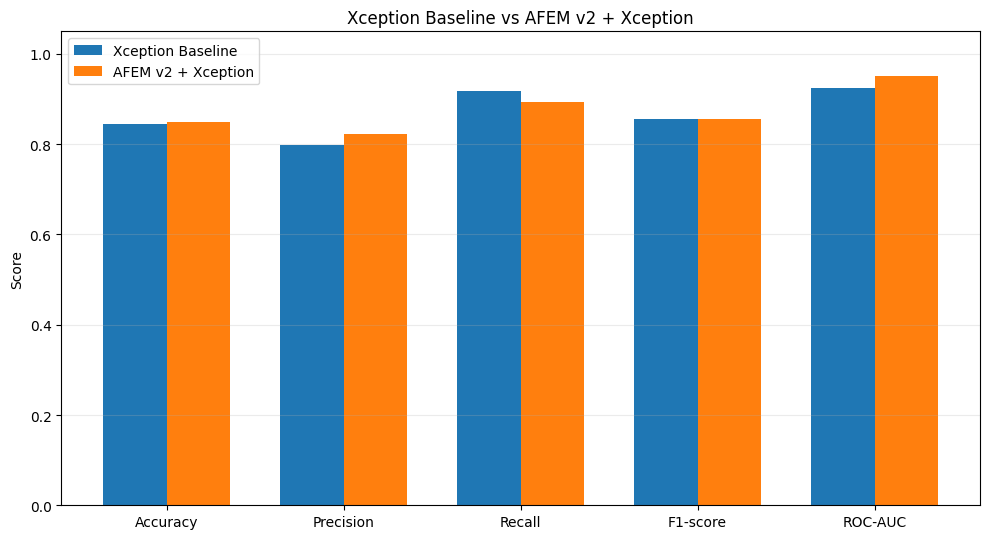

Figure saved to: /content/drive/MyDrive/deepfake-defense/reports/model_comparison.png


In [17]:

import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

metrics = ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]

baseline = [0.8438, 0.7989, 0.9187, 0.8547, 0.9237]
afem =     [0.8500, 0.8218, 0.8938, 0.8563, 0.9504]

x = np.arange(len(metrics))
width = 0.36

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(x - width/2, baseline, width, label="Xception Baseline")
ax.bar(x + width/2, afem, width, label="AFEM v2 + Xception")

ax.set_ylabel("Score")
ax.set_title("Xception Baseline vs AFEM v2 + Xception")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()

figure_path = Path(
    "/content/drive/MyDrive/deepfake-defense/"
    "reports/model_comparison.png"
)
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print("Figure saved to:", figure_path)
